# House Prices Prediction using scikit-learn

This notebook walks you through how to train a baseline Random Forest model using scikit-learn on the House Prices dataset made available for this competition.

Roughly, the code will look as follows:

```
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

dataset = pd.read_csv("project/dataset.csv")
X, y = dataset.drop(columns="my_label"), dataset["my_label"]

model = RandomForestRegressor()
model.fit(X, y)  # after encoding categorical features and imputing missing values
```

Random Forests and Gradient Boosted Trees are tree-based models. They are the best place to start when working with tabular data, and will often outperform (or provide a strong baseline) before you begin experimenting with neural networks.

## Import the library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import plot_tree

# Comment this if the data visualisations doesn't work on your side
%matplotlib inline

In [2]:
print("scikit-learn v" + sklearn.__version__)

scikit-learn v1.9.1


## Load the dataset

In [3]:
DATA_DIR = "./../house-prices-advanced-regression-techniques"

train_file_path = f"{DATA_DIR}/train.csv"
dataset_df = pd.read_csv(train_file_path)
print("Full train dataset shape is {}".format(dataset_df.shape))

Full train dataset shape is (1460, 81)


The data is composed of 81 columns and 1460 entries. We can see all 81 dimensions of our dataset by printing out the first 3 entries using the following code:

In [4]:
dataset_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


* There are 79 feature columns. Using these features your model has to predict the house sale price indicated by the label column named `SalePrice`.

We will drop the `Id` column as it is not necessary for model training.

In [5]:
dataset_df = dataset_df.drop('Id', axis=1)
dataset_df.head(3)

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


We can inspect the types of feature columns using the following code:

In [6]:
dataset_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

## House Price Distribution

Now let us take a look at how the house prices are distributed.

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


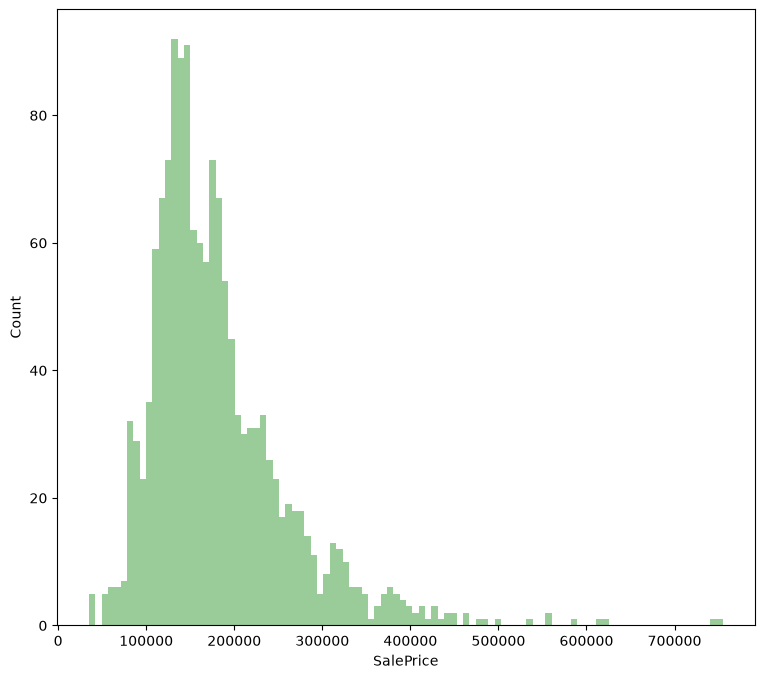

In [7]:
print(dataset_df['SalePrice'].describe())
plt.figure(figsize=(9, 8))
plt.hist(dataset_df['SalePrice'], color='g', bins=100, alpha=0.4)
plt.xlabel('SalePrice')
plt.ylabel('Count')
plt.show()

## Numerical data distribution

We will now take a look at how the numerical features are distributed. In order to do this, let us first list all the types of data from our dataset and select only the numerical ones.

In [8]:
list(set(dataset_df.dtypes.tolist()))

[dtype('int64'),
 <StringDtype(storage='python', na_value=nan)>,
 dtype('float64')]

In [9]:
df_num = dataset_df.select_dtypes(include = ['float64', 'int64'])
df_num.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000


Now let us plot the distribution for all the numerical features.

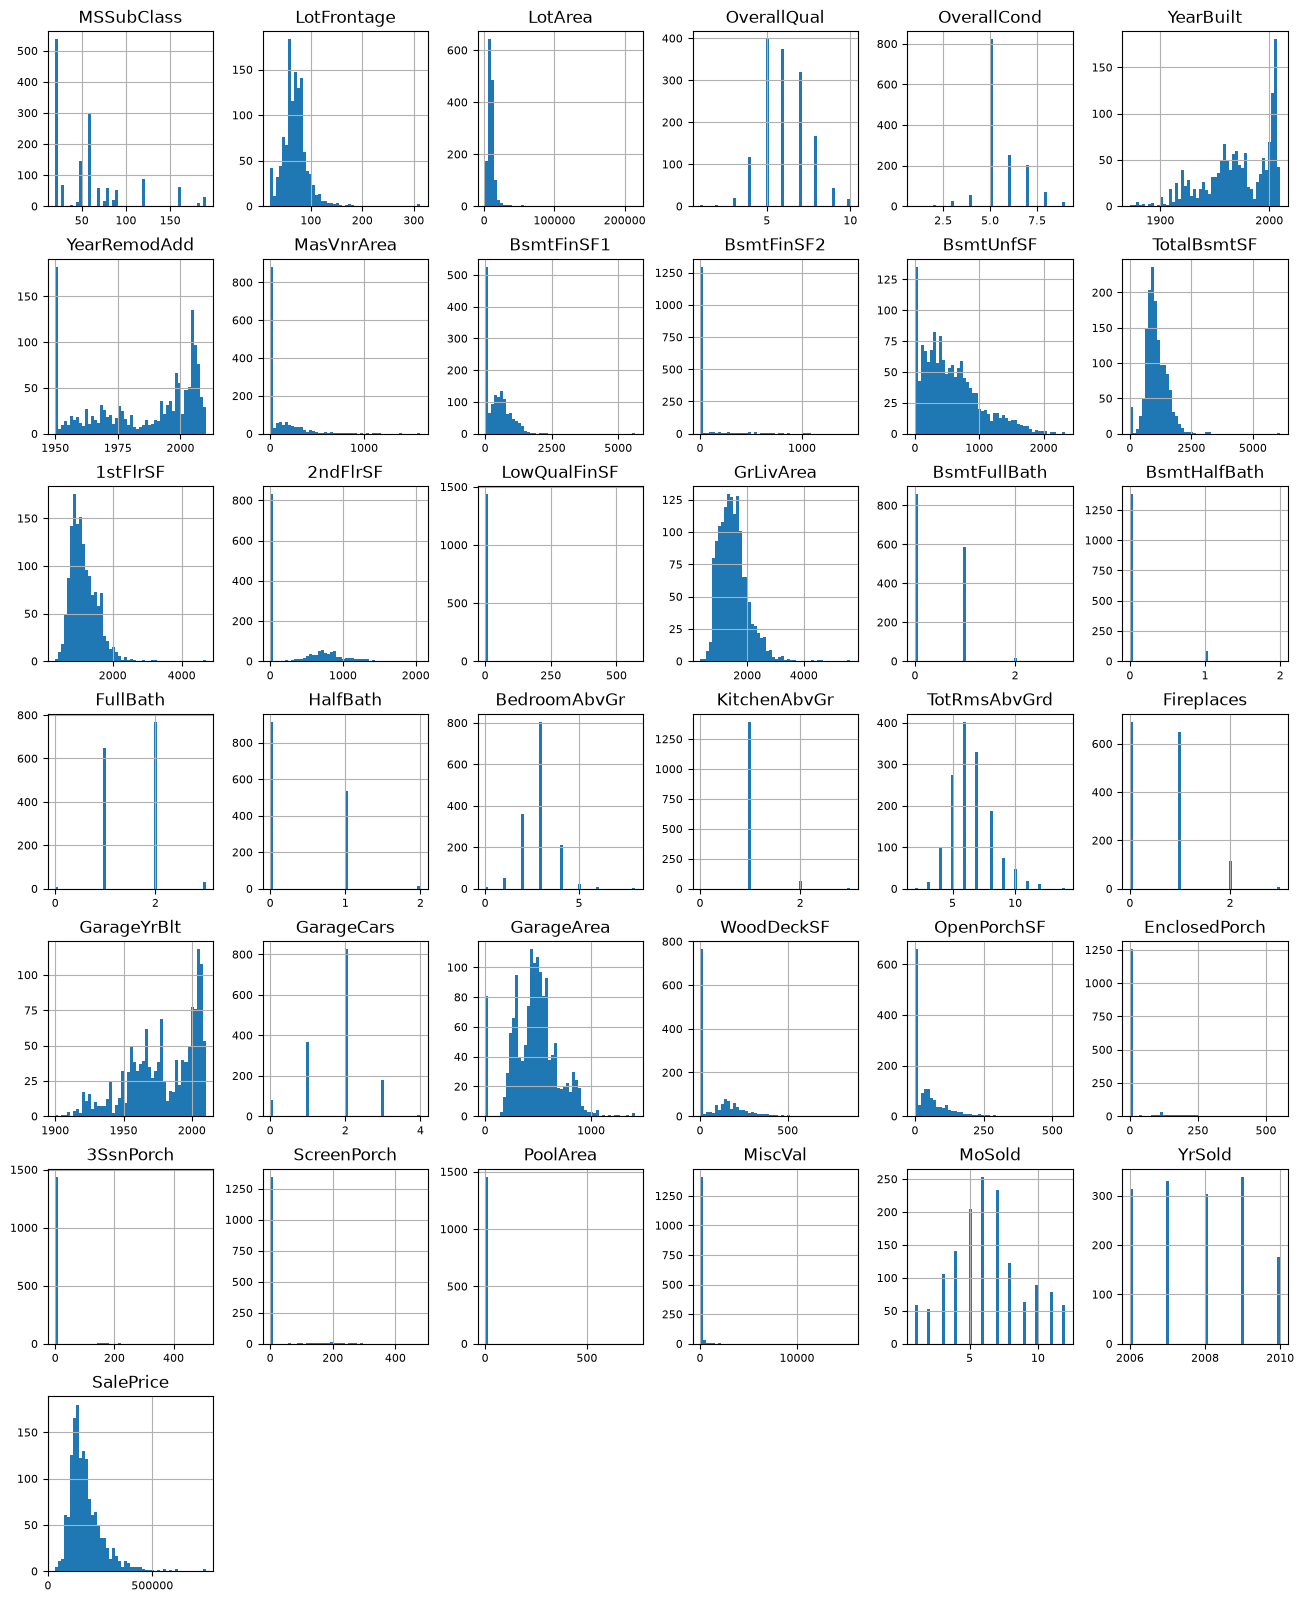

In [10]:
df_num.hist(figsize=(16, 20), bins=50, xlabelsize=8, ylabelsize=8);

## Prepare the dataset

This dataset contains a mix of numeric, categorical and missing features. Unlike TF-DF, scikit-learn's `RandomForestRegressor` needs purely numeric input, so we will have to:

* impute the missing values (median for numeric features, a `"missing"` category for categorical ones, since in this dataset a missing categorical value usually means "this house doesn't have that feature"),
* encode the categorical features as numbers.

Tree-based models don't need feature scaling, so that is all the preprocessing required.

First, let us separate the label from the features and split the dataset into training and testing datasets:

In [11]:
label = 'SalePrice'
X = dataset_df.drop(columns=label)
y = dataset_df[label]

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.30, random_state=42)
print("{} examples in training, {} examples in testing.".format(
    len(X_train), len(X_valid)))

1022 examples in training, 438 examples in testing.


There's one more step required before we can train the model: building the preprocessing step described above.

We use a `ColumnTransformer` so that the exact same transformation, fitted on the training set only, can later be applied to the validation and test sets. Categories never seen during training are encoded as `-1`.

In [12]:
numeric_pipe = SimpleImputer(strategy="median")

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipe, make_column_selector(dtype_include="number")),
        ("cat", categorical_pipe, make_column_selector(dtype_exclude="number")),
    ],
    verbose_feature_names_out=False,
)

X_train_p = preprocessor.fit_transform(X_train)
X_valid_p = preprocessor.transform(X_valid)
feature_names = preprocessor.get_feature_names_out()

print("Processed training matrix shape:", X_train_p.shape)

Processed training matrix shape: (1022, 79)


## Select a Model

There are several tree-based models for you to choose from, for example:

* RandomForestRegressor
* ExtraTreesRegressor
* GradientBoostingRegressor
* HistGradientBoostingRegressor
* DecisionTreeRegressor

To start, we'll work with a Random Forest. This is the most well-known of the tree ensemble training algorithms.

A Random Forest is a collection of decision trees, each trained independently on a random subset of the training dataset (sampled with replacement). The algorithm is unique in that it is robust to overfitting, and easy to use.

We can list the tree-based regressors available in scikit-learn using the following code:

In [13]:
from sklearn.utils import all_estimators

[name for name, _ in all_estimators(type_filter="regressor")
 if any(key in name for key in ("Forest", "Boost", "Tree"))]

['AdaBoostRegressor',
 'DecisionTreeRegressor',
 'ExtraTreeRegressor',
 'ExtraTreesRegressor',
 'GradientBoostingRegressor',
 'HistGradientBoostingRegressor',
 'RandomForestRegressor']

## How can I configure them?

scikit-learn's defaults are reasonable but not tuned for this kind of data. For a Random Forest, the hyperparameters that matter most are:

* `n_estimators`: number of trees (default 100),
* `max_features`: fraction of features considered at each split (default 1.0 for regression),
* `min_samples_leaf`: minimum number of samples in a leaf (default 1),
* `max_depth`: maximum depth of each tree (default unlimited).

Below we use 300 trees, a third of the features at each split and at least 5 samples per leaf, which is close to the usual Random Forest settings for regression.

Read more [here](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

## Create a Random Forest

We use `RandomForestRegressor` (the regression counterpart of `RandomForestClassifier`) and ask it to compute the Out of bag (OOB) score while training.

In [14]:
rf_params = dict(
    n_estimators=300,
    max_features=1/3,
    min_samples_leaf=5,
    oob_score=True,
    n_jobs=-1,
    random_state=42,
)
rf = RandomForestRegressor(**rf_params)

## Train the model

We will train the model using a one-liner.

In [15]:
rf.fit(X_train_p, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.3333333333333333
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.r2_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If flo

## Visualize the model
One benefit of tree-based models is that you can easily visualize them. We configured the forest with 300 trees. We can select a tree to display below.

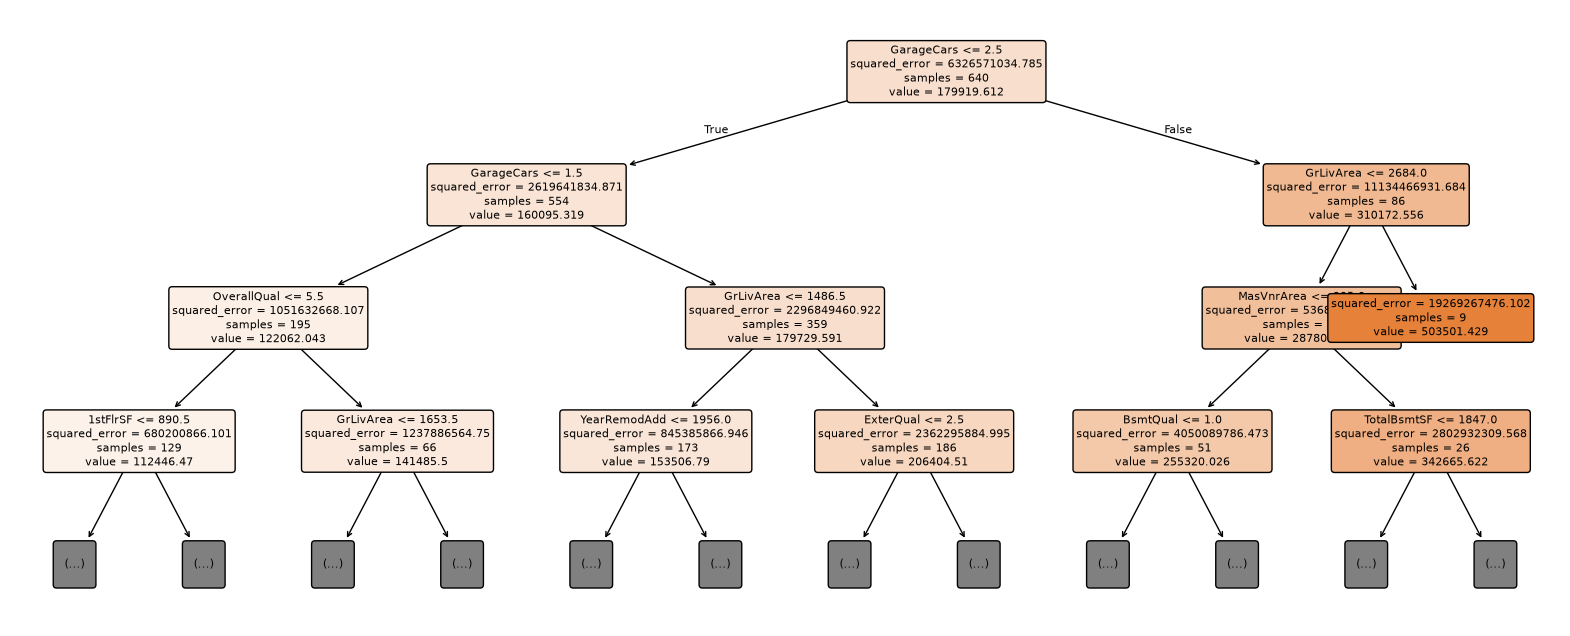

In [16]:
plt.figure(figsize=(20, 8))
plot_tree(rf.estimators_[0], max_depth=3, feature_names=list(feature_names),
          filled=True, rounded=True, fontsize=8)
plt.show()

## Evaluate the model on the Out of bag (OOB) data and the validation dataset

Before training the model we have manually separated 30% of the dataset for validation named as `X_valid` / `y_valid`.

We can also use Out of bag (OOB) score to validate our Random Forest.
To train a Random Forest, a set of random samples from the training set are chosen by the algorithm for each tree and the rest of the samples are not used to train that tree. The subset of data that is not chosen is known as Out of bag data (OOB).
OOB score is computed on the OOB data.

Read more about OOB data [here](https://developers.google.com/machine-learning/decision-forests/out-of-bag).

scikit-learn doesn't keep a training log, so to plot the Root Mean Squared Error (RMSE) evaluated on the out-of-bag data according to the number of trees, we grow a forest incrementally with `warm_start=True` and record the OOB RMSE along the way. Let us plot this.

Note: Smaller values are better for this metric.

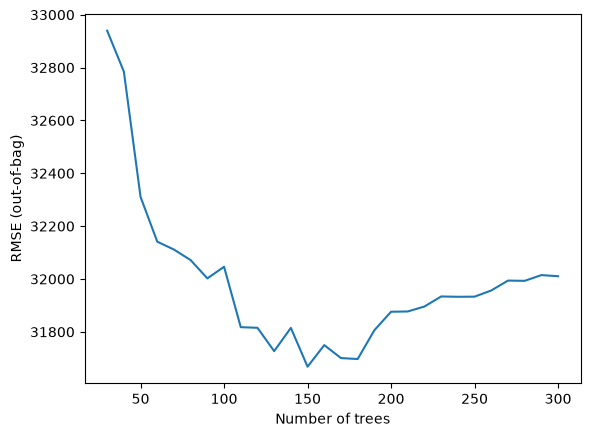

In [17]:
rf_curve = RandomForestRegressor(**{**rf_params, "warm_start": True})

n_trees, oob_rmse_curve = [], []
for n in range(30, rf_params["n_estimators"] + 1, 10):
    rf_curve.set_params(n_estimators=n)
    rf_curve.fit(X_train_p, y_train)
    n_trees.append(n)
    oob_rmse_curve.append(np.sqrt(mean_squared_error(y_train, rf_curve.oob_prediction_)))

plt.plot(n_trees, oob_rmse_curve)
plt.xlabel("Number of trees")
plt.ylabel("RMSE (out-of-bag)")
plt.show()

We can also see some general stats on the OOB dataset:

In [18]:
oob_rmse = np.sqrt(mean_squared_error(y_train, rf.oob_prediction_))
print(f"OOB RMSE: {oob_rmse:.4f}")
print(f"OOB R2:   {rf.oob_score_:.4f}")

OOB RMSE: 32010.5042
OOB R2:   0.8297


Now, let us run an evaluation using the validation dataset.

In [19]:
valid_pred = rf.predict(X_valid_p)
mse = mean_squared_error(y_valid, valid_pred)
evaluation = {"mse": mse, "rmse": np.sqrt(mse), "r2": r2_score(y_valid, valid_pred)}

for name, value in evaluation.items():
  print(f"{name}: {value:.4f}")

mse: 824281188.7170
rmse: 28710.2976
r2: 0.8819


## Variable importances

Variable importances generally indicate how much a feature contributes to the model predictions or quality. There are several ways to identify important features using scikit-learn.
Let us list the available `Variable Importances` for a Random Forest:

* `feature_importances_`: impurity-based importance (mean decrease in impurity, MDI), computed during training,
* `permutation_importance`: drop in validation score when a feature's values are shuffled.

Impurity-based importance is known to favour features with many distinct values (such as ordinal-encoded categoricals), so permutation importance is a useful cross-check.

In [20]:
print("Available variable importances:")
print("\t feature_importances_ (MDI)")
print("\t permutation_importance")

Available variable importances:
	 feature_importances_ (MDI)
	 permutation_importance


As an example, let us display the important features for the impurity-based importance (MDI).

The larger the importance score, the more impact the feature has on the outcome of the model.

By default we sort the list from the most important to the least.

In [21]:
mdi_df = (pd.DataFrame({"feature": feature_names, "importance": rf.feature_importances_})
            .sort_values("importance", ascending=False)
            .reset_index(drop=True))
mdi_df.head(10)

,feature,importance
0,OverallQual,0.264641
1,GrLivArea,0.142200
2,GarageCars,0.096508
3,ExterQual,0.054390
4,YearBuilt,0.049458
5,TotalBsmtSF,0.044278
6,1stFlrSF,0.037385
7,GarageArea,0.036199
8,BsmtQual,0.035718
9,BsmtFinSF1,0.029426


Let us also compute the permutation importance on the validation set, and plot both with Matplotlib

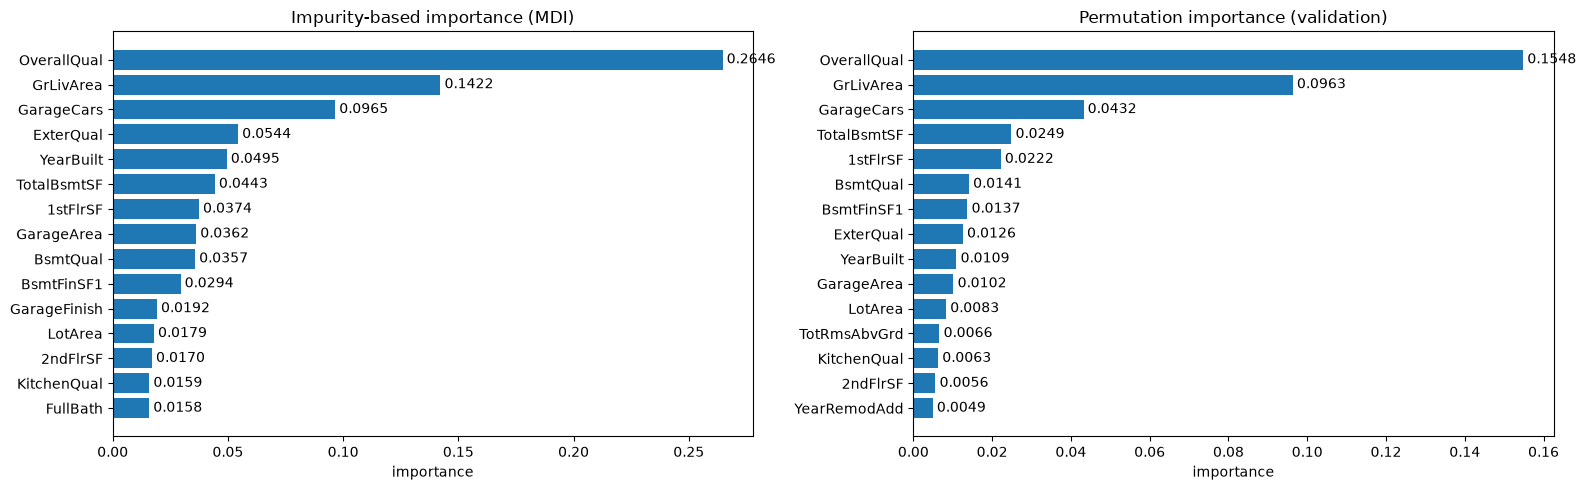

In [22]:
perm = permutation_importance(rf, X_valid_p, y_valid, n_repeats=10, random_state=42, n_jobs=-1)
perm_df = (pd.DataFrame({"feature": feature_names, "importance": perm.importances_mean})
             .sort_values("importance", ascending=False)
             .reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, df_imp, title in zip(
        axes,
        (mdi_df, perm_df),
        ("Impurity-based importance (MDI)", "Permutation importance (validation)")):
    top = df_imp.head(15)
    bar = ax.barh(range(len(top)), top["importance"])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top["feature"])
    ax.invert_yaxis()
    # Label each bar with its value
    ax.bar_label(bar, fmt="%.4f", padding=3)
    ax.set_title(title)
    ax.set_xlabel("importance")

plt.tight_layout()
plt.show()

# Submission
Finally predict on the competition test data using the model.

In [23]:
test_file_path = f"{DATA_DIR}/test.csv"
test_data = pd.read_csv(test_file_path)
ids = test_data.pop('Id')

# Same preprocessing as for the training data (fitted on the training set only)
test_p = preprocessor.transform(test_data)

preds = rf.predict(test_p)
output = pd.DataFrame({'Id': ids,
                       'SalePrice': preds.squeeze()})

output.head()

,Id,SalePrice
0,1461,126247.286829
1,1462,148830.378978
2,1463,186133.441434
3,1464,188865.401469
4,1465,205804.974275


In [24]:
sample_submission_df = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
sample_submission_df['SalePrice'] = preds
sample_submission_df.to_csv('submission.csv', index=False)
sample_submission_df.head()

,Id,SalePrice
0,1461,126247.286829
1,1462,148830.378978
2,1463,186133.441434
3,1464,188865.401469
4,1465,205804.974275
